# Metacom5_3 人类联合评审与 ChatGPT 探索性评审

2026-09-17 · 描述性分析 · 不产生正式标签或裁判资格结论。

两份原文身份与完整性均通过。80 个基础配对中，人类 56 个相当、AI 34 个相当；一致 27/80。人类反序 15/16，AI 16/16。这不是两位独立人类的一致性。现存中文 HTML 有 pet→猫/狗的翻译错误。

## 方法与输入

按 presentation_id 对齐，保留原始非反序的 80 对；16 个反序仅用于稳定性。DG 27 对共享 9 个情境，不能当作独立 27 个场景。原始评分不改；AI 不是 gold。下方脚本复查冻结题目并重算全部统计。依赖、源码和输入路径都保留；中文译文只做了重点抽核。

In [1]:
from pathlib import Path
import json, subprocess, sys, hashlib
OUT=Path('/home/tokkio/人评结果分析_20260917')
run=subprocess.run(['/opt/tokkio-data0/tokkio_envs/paper1-py311/bin/python',str(OUT/'analyze_ratings.py')],capture_output=True,text=True,check=True)
S=json.loads((OUT/'summary.json').read_text())
rows=json.loads((OUT/'aligned_ratings.json').read_text())
assert S['canonical_base_pairs_80']['n']==80
assert S['presentations_96']['n']==96
print('原始结构与必填验证:',S['validation'])
print('原始文件 SHA-256:')
for k in ['A_source','B_source']: print(k,S['provenance'][k]['sha256'])

原始结构与必填验证: {'A': {'valid': True, 'presentations': 96, 'completed': 96}, 'B': {'valid': True, 'presentations': 96, 'completed': 96}}
原始文件 SHA-256:
A_source 0272f503c61811484c9b7da2c6bb25e331538376bd0e1b683e4f2dd3c6e5a94b
B_source d956751629e08d11511dd5efa7b1060ab5957796e5f6012b214ac0e1b6ad6c92


## 80 个基础配对的判断

方向是每个规范呈现的左右 A/B，不是人类/AI，也不是 ON/OFF。相当可以包括两者同样差。

In [2]:
import pandas as pd
from IPython.display import display
labels=['A_better','B_better','equivalent','uncertain']
base=S['canonical_base_pairs_80']
display(pd.DataFrame({'Human joint A':[base['human_counts'].get(x,0) for x in labels],'ChatGPT B':[base['ai_counts'].get(x,0) for x in labels]},index=labels))
display(pd.DataFrame([{'Task':t,'N':d['n'],'Human equivalent':d['human_counts'].get('equivalent',0),'AI equivalent':d['ai_counts'].get('equivalent',0),'Agreement':f"{d['agreement']}/{d['n']}"} for t,d in S['by_task_80'].items()]))

,Human joint A,ChatGPT B
A_better,2,25
B_better,10,20
equivalent,56,34
uncertain,12,1


,Task,N,Human equivalent,AI equivalent,Agreement
0,ESC,27,25,19,17/27
1,QA,13,1,8,3/13
2,Summary,13,6,3,2/13
3,DG,27,24,4,5/27


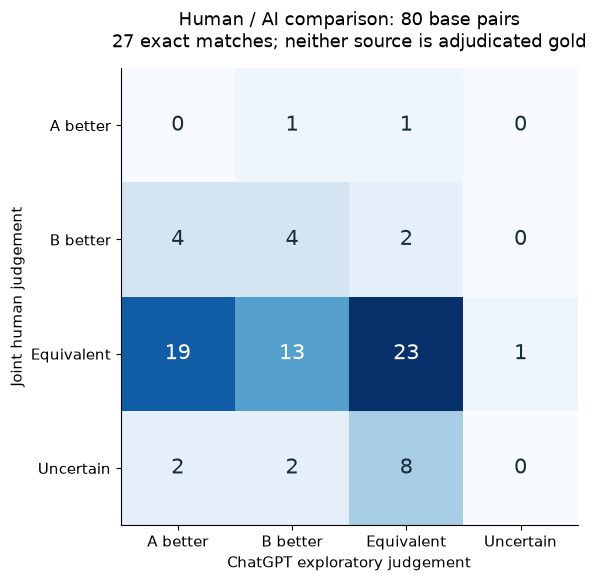

In [3]:
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.spines.top':False,'axes.spines.right':False})
fig,ax=plt.subplots(figsize=(7.5,5.7),layout='constrained')
m=np.array([[base['confusion_human_rows_ai_columns'][a][b] for b in labels] for a in labels])
ax.imshow(m,cmap='Blues',vmin=0,vmax=max(m.max(),1))
for i in range(4):
 for j in range(4):ax.text(j,i,str(m[i,j]),ha='center',va='center',color='white' if m[i,j]>m.max()/2 else '#182b3a',fontsize=15)
ax.set_xticks(range(4),['A better','B better','Equivalent','Uncertain']);ax.set_yticks(range(4),['A better','B better','Equivalent','Uncertain'])
ax.set_xlabel('ChatGPT exploratory judgement');ax.set_ylabel('Joint human judgement')
ax.set_title('Human / AI comparison: 80 base pairs\n27 exact matches; neither source is adjudicated gold',pad=15)
fig.savefig(OUT/'human_ai_confusion.png',dpi=180,bbox_inches='tight')
plt.show()

AI 在人类判相当的 56 对中仅 23 对也判相当，32 对选了胜者，1 对无法判断。这个差异提示需要核对实质优势的尺度及事实；不能称 AI 准确率 33.75%，也不能只追求总体一致率。总判相当会得到 56/80 的表面一致率，仍不是合格裁判的证明。

## 原始生成的长度上限

以下为唯一生成调用，DG 的 OFF 共享，故其分母是 9 而不是 27。finish_reason=length 表示触及上限，不保证每条显示文字都在半句处截断。

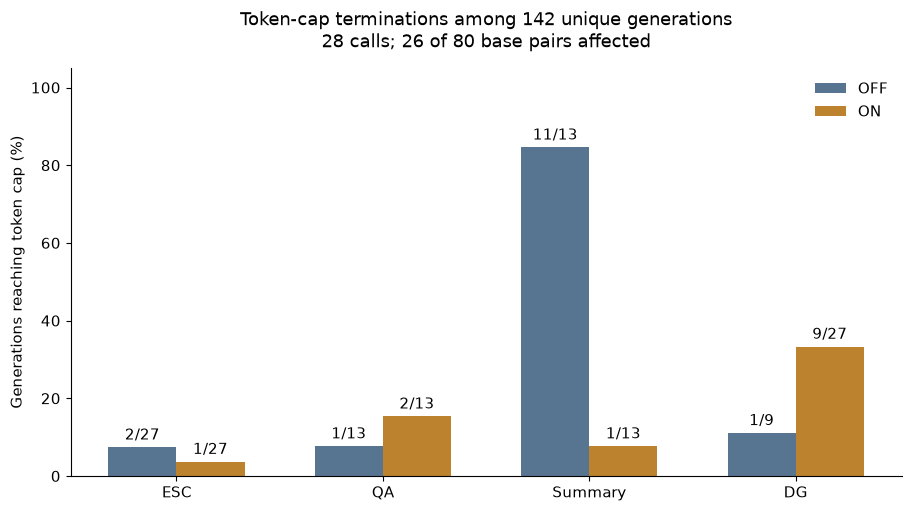

In [4]:
g=S['generation_unique']['by_task_arm'];tasks=['ESC','QA','Summary','DG']
fig,ax=plt.subplots(figsize=(9,5),layout='constrained')
x=np.arange(4);width=.33
for arm,offset,color in [('OFF',-width/2,'#577591'),('ON',width/2,'#bd822e')]:
 vals=[100*g[t+'_'+arm]['length']/g[t+'_'+arm]['n'] for t in tasks]
 bars=ax.bar(x+offset,vals,width,label=arm,color=color)
 for bar,t in zip(bars,tasks):
  d=g[t+'_'+arm];ax.text(bar.get_x()+bar.get_width()/2,bar.get_height()+2,f"{d['length']}/{d['n']}",ha='center',fontsize=11)
ax.set_ylim(0,105);ax.set_xticks(x,tasks);ax.set_ylabel('Generations reaching token cap (%)')
ax.set_title('Token-cap terminations among 142 unique generations\n28 calls; 26 of 80 base pairs affected',pad=15);ax.legend(frameon=False)
fig.savefig(OUT/'generation_length_caps.png',dpi=180,bbox_inches='tight');plt.show()

Summary OFF 11/13 触限，ON 1/13。QA/Summary 本批最大输出为 256 tokens。回复中有分析步骤和提示示例复述，不能靠删掉坏样本或补写回复来提升人评一致性。

In [5]:
reverse=json.loads((OUT/'reverse_consistency.json').read_text())
print('反序一致:', S['reversal'])
display(pd.DataFrame([r for r in reverse if not r['human_consistent']])[['task','human_items','human_original','human_reverse']])
print('HTML 历史译文方法:',json.loads((OUT/'translation_findings.json').read_text())['history_method'])
print('执行通过；无正式 effect、无训练、无付费模型调用。')

反序一致: {'n': 16, 'human': 15, 'ai': 16}


,task,human_items,human_original,human_reverse
0,Summary,"[78, 13]",uncertain,A_better


HTML 历史译文方法: local NLLB-200-distilled-600M; machine translation with selected corrections; not fully human reviewed
执行通过；无正式 effect、无训练、无付费模型调用。


## 使用边界

完整结论及后续方案见同目录《分析报告.md》。保留联合人类记录与探索性 AI 记录；二者不能冒充两份独立人评。对现有评分的澄清应单独记录，并披露已经见过 AI 结果。任何减少主评要求、修改语言材料、修改生成上限的正式变更，都需要单独研究决定。